[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/getting-started/setup/notebook.ipynb)

# Setup: check your environment

This notebook goes with the [topic README](README.md). It answers three questions from inside a notebook: **which Python is running, which libraries does it have, and can it draw a plot?** Run it after you have set up an environment (or open it in Colab with the badge above) and compare the output with what you expect.

Run the cells from top to bottom with `Shift+Enter`. The notebook needs only NumPy and Matplotlib and finishes in a second or two.

## 1. Which Python is this?

A notebook runs on a **kernel**, a Python process tied to one environment. The kernel's Python decides which packages you can import, so this is the first thing to check when an `import` fails.

In [1]:
import os
import platform
import sys

print("Python version   :", platform.python_version())
print("Operating system :", platform.system())
print("Environment name :", os.path.basename(sys.prefix))
print("Running in Colab :", "google.colab" in sys.modules)

# To see the full path of the interpreter, remove the # in front of the next line:
# print("Interpreter path :", sys.executable)

Python version   : 3.11.16
Operating system : Linux
Environment name : aiml
Running in Colab : False


Read the environment name. If you expected `ai-roadmap` or `.venv` and see something else, you are probably using the wrong kernel. In VS Code, click **Select Kernel** at the top right; in Jupyter, use the **Kernel** menu. The full path from `sys.executable` is even more precise: it should point inside your environment folder.

## 2. Are the libraries installed?

The function below looks for each package and prints its version, or says that it is missing, instead of crashing. Add package names to the list to check more.

In [2]:
from importlib import metadata
from importlib.util import find_spec


def check_packages(names):
    """Print the installed version of each package, or MISSING."""
    for name in names:
        if find_spec(name) is None:
            print(f"{name:<20} MISSING")
        else:
            print(f"{name:<20} {metadata.version(name)}")


check_packages(["numpy", "matplotlib", "scipy", "sympy", "not_a_real_package"])

numpy                2.4.6
matplotlib           3.11.2
scipy                1.17.1
sympy                1.13.1
not_a_real_package   MISSING


`not_a_real_package` is there on purpose, to show what a missing package looks like. If a real package such as `numpy` says `MISSING`, install it from inside the notebook so that it goes into this kernel's environment:

```python
%pip install numpy
```

(Do not run it if the package is already there. In Colab, NumPy and Matplotlib are preinstalled.)

## 3. Can it draw a plot?

The last check is a tiny plot with NumPy and Matplotlib. If the plot appears under the cell, the libraries work together.

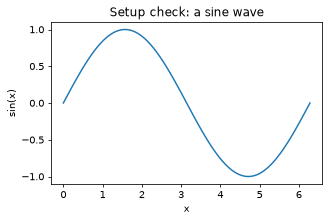

NumPy 2.4.6 | Matplotlib 3.11.2


In [3]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70

x = np.linspace(0, 2 * np.pi, 100)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(x, np.sin(x))
ax.set_title("Setup check: a sine wave")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
plt.show()

print("NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)

## What to do with the result

- All three checks pass: you are ready for [Python Basics](../python-basics/README.md).
- A version or environment name surprises you: fix the kernel, as described in the README's troubleshooting table.
- A package is `MISSING`: install it into the environment that this kernel uses, then restart the kernel and run the notebook again.

Then try the [exercises](exercises/problems.md) and the [assignment](assignment.md).